SANTIAGO DIE MOREJÓN - 23/04/2026 - IA - Entregable 2 Adicional 1 - Arquitecturas

# Notebook 2: Comparativa de Arquitecturas

En este notebook comparamos distintas arquitecturas de redes neuronales convolucionales aplicadas al mismo problema de clasificación de imágenes satelitales (cloudy, desert, green_area, water).

## 0. Instalación y carga de librerías

In [1]:
!pip install fastai timm -Uq

In [2]:
from fastai.vision.all import *
import timm
import os
import shutil
import time
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

## 1. Carga y preparación del dataset

Usamos el mismo dataset de imágenes satelitales del notebook principal.

In [3]:
!wget DATA_URL -O archive.zip
!unzip -q archive.zip

--2026-04-27 19:20:43--  DATA_URL
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 22836290 (22M) [application/zip]
Saving to: ‘archive.zip’

archive.zip         100%[===================>]  21.78M  --.-KB/s    in 0.1s    

2026-04-27 19:20:44 (206 MB/s) - ‘archive.zip’ saved [22836290/22836290]



In [4]:
os.makedirs('/content/data/satellite/train', exist_ok=True)
os.makedirs('/content/data/satellite/test', exist_ok=True)

for c in ['cloudy', 'desert', 'green_area', 'water']:
    os.makedirs(f'/content/data/satellite/train/{c}', exist_ok=True)
    os.makedirs(f'/content/data/satellite/test/{c}', exist_ok=True)

In [5]:
path = Path('/content/data')

In [6]:
for im in verify_images(get_image_files('/content/data')):
    os.remove(str(im))

In [7]:
from sklearn.model_selection import train_test_split

trainCloudy,   testCloudy   = train_test_split(get_image_files(path/'cloudy'),    test_size=0.2, random_state=15)
trainDesert,   testDesert   = train_test_split(get_image_files(path/'desert'),    test_size=0.2, random_state=15)
trainGreen,    testGreen    = train_test_split(get_image_files(path/'green_area'),test_size=0.2, random_state=15)
trainWater,    testWater    = train_test_split(get_image_files(path/'water'),     test_size=0.2, random_state=15)

In [8]:
for x in trainCloudy:
    shutil.move(str(x), path/('satellite/train/cloudy/'+x.name))

for x in trainDesert:
    shutil.move(str(x), path/('satellite/train/desert/'+x.name))

for x in trainGreen:
    shutil.move(str(x), path/('satellite/train/green_area/'+x.name))

for x in trainWater:
    shutil.move(str(x), path/('satellite/train/water/'+x.name))


In [9]:
for x in testCloudy:
    shutil.move(str(x), path/('satellite/test/cloudy/'+x.name))

for x in testDesert:
    shutil.move(str(x), path/('satellite/test/desert/'+x.name))

for x in testGreen:
    shutil.move(str(x), path/('satellite/test/green_area/'+x.name))

for x in testWater:
    shutil.move(str(x), path/('satellite/test/water/'+x.name))

In [10]:
shutil.rmtree(path/'cloudy')
shutil.rmtree(path/'desert')
shutil.rmtree(path/'green_area')
shutil.rmtree(path/'water')

## 2. Selección de arquitecturas

Para la seleccion de las distintas arquitecturas de redes neuranoles voy a explorar el catálogo de [timm](https://wandb.ai/capecape/imagenette_timm/reports/Checking-Out-the-New-fastai-timm-Integration--VmlldzoxOTMzNzMw)

In [11]:
import timm

todas = timm.list_models(pretrained=True)
print(f"Total de arquitecturas preentrenadas: {len(todas)}\n")

Total de arquitecturas preentrenadas: 1699



In [12]:
for familia in ['resnet*', 'efficientnet*', 'mobilenet*', 'convnext*', 'vit*', 'densenet*']:
    modelos = timm.list_models(familia, pretrained=True)
    print(f"{familia} : {len(modelos)} modelos")

resnet* : 130 modelos
efficientnet* : 23 modelos
mobilenet* : 43 modelos
convnext* : 95 modelos
vit* : 338 modelos
densenet* : 6 modelos


He seleccionado las siguientes arquitecturas
| Arquitectura | Familia | Justificación |
|---|---|---|
| `resnet18` | ResNet | Aqruitectura que usamos en el notebook principal.|
| `resnet34` | ResNet | Misma familia pero más profunda. |
| `efficientnet_b0` | EfficientNet | Arquitectura con buen ratio accuracy/parámetros. |
| `mobilenetv3_small_100` | MobileNet | La más ligera del catálogo.  |
| `convnext_tiny` | ConvNeXt | Arquitectura moderna . |



# 3. Creacion de metodo auxiliar para entrener y evaluar el modelo

In [13]:
def entrenar_arquitectura(arch_name):
    dls = ImageDataLoaders.from_folder(path/'satellite'/'train',
        valid_pct=0.2, seed=42,
        item_tfms=Resize(224),
        batch_tfms=aug_transforms(size=224, min_scale=0.75), bs=32)

    learn = vision_learner(dls, arch_name, metrics=[accuracy, error_rate])

    t0 = time.time()
    learn.fine_tune(5)
    elapsed = round(time.time() - t0, 1)

    val_loss, acc, err = learn.validate()
    n_params = sum(p.numel() for p in learn.model.parameters() if p.requires_grad)

    result = {
        'Arquitectura':    getattr(arch_name, '__name__', arch_name),
        'Accuracy':        round(float(acc), 4),
        'Error Rate':      round(float(err), 4),
        'Val Loss':        round(float(val_loss), 4),
        'Tiempo (s)':      elapsed,
        'Parámetros (M)':  round(n_params / 1e6, 2)
    }
    print(result)
    return result, learn

## 4. Entrenamiento de cada arquitectura

Entrenamos cada arquitectura durante 5 epochs con las mismas condiciones para que la comparativa sea justa.

### 4.1 ResNet18

In [14]:
res18, learn_res18 = entrenar_arquitectura(resnet18)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 116MB/s]


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.295494,0.022816,0.995556,0.004444,00:16


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.120554,0.014612,0.996667,0.003333,00:18
1,0.084947,0.046582,0.985556,0.014444,00:17
2,0.036540,0.004786,0.997778,0.002222,00:17
3,0.040748,0.001876,1.000000,0.000000,00:19
4,0.015191,0.002868,0.998889,0.001111,00:17


{'Arquitectura': 'resnet18', 'Accuracy': 0.9989, 'Error Rate': 0.0011, 'Val Loss': 0.0029, 'Tiempo (s)': 107.8, 'Parámetros (M)': 11.71}


### 4.2 ResNet34

In [15]:
res34, learn_res34 = entrenar_arquitectura(resnet34)

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 150MB/s]


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.297833,0.021688,0.993333,0.006667,00:19


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.087447,0.043943,0.988889,0.011111,00:26
1,0.085909,0.003382,0.998889,0.001111,00:25
2,0.046969,0.008119,0.996667,0.003333,00:25
3,0.023619,0.000591,1.000000,0.000000,00:25
4,0.012393,0.000838,1.000000,0.000000,00:25


{'Arquitectura': 'resnet34', 'Accuracy': 1.0, 'Error Rate': 0.0, 'Val Loss': 0.0008, 'Tiempo (s)': 148.1, 'Parámetros (M)': 21.81}


### 4.3 EfficientNet-B0


In [16]:
eff_b0, learn_eff = entrenar_arquitectura('efficientnet_b0')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.291604,0.379703,0.907778,0.092222,00:21


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.128343,0.196199,0.947778,0.052222,00:26
1,0.114524,0.474574,0.884444,0.115556,00:26
2,0.080830,0.143387,0.958889,0.041111,00:26
3,0.062520,0.111372,0.967778,0.032222,00:26
4,0.061200,0.108912,0.971111,0.028889,00:25


{'Arquitectura': 'efficientnet_b0', 'Accuracy': 0.9711, 'Error Rate': 0.0289, 'Val Loss': 0.1089, 'Tiempo (s)': 152.3, 'Parámetros (M)': 5.33}


### 4.4 MobileNetV3 Small


In [17]:
mob_v3, learn_mob = entrenar_arquitectura('mobilenetv3_small_100')

model.safetensors:   0%|          | 0.00/10.2M [00:00<?, ?B/s]

epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.219191,154.673767,0.957778,0.042222,00:15


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.096690,0.114900,0.973333,0.026667,00:17
1,0.099145,1747.795532,0.973333,0.026667,00:18
2,0.069188,0.026285,0.990000,0.010000,00:17
3,0.061446,0.098927,0.975556,0.024444,00:19
4,0.045517,137.190170,0.972222,0.027778,00:17


{'Arquitectura': 'mobilenetv3_small_100', 'Accuracy': 0.9722, 'Error Rate': 0.0278, 'Val Loss': 137.1902, 'Tiempo (s)': 104.6, 'Parámetros (M)': 2.11}


### 4.5 ConvNeXt Tiny


In [18]:
convnext, learn_cnx = entrenar_arquitectura('convnext_tiny')

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.134207,0.034664,0.986667,0.013333,00:44


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.050197,0.017780,0.993333,0.006667,01:05
1,0.032000,0.036419,0.988889,0.011111,01:09
2,0.022403,0.005828,0.998889,0.001111,01:09
3,0.007760,0.003581,0.997778,0.002222,01:06
4,0.001441,0.000852,1.000000,0.000000,01:07


{'Arquitectura': 'convnext_tiny', 'Accuracy': 1.0, 'Error Rate': 0.0, 'Val Loss': 0.0009, 'Tiempo (s)': 382.6, 'Parámetros (M)': 28.61}


## 5. Comparativa de resultados

Reunimos todos los resultados en un único DataFrame y lo visualizamos.

In [19]:
df = pd.DataFrame([res18, res34, eff_b0, mob_v3, convnext])
df = df.sort_values('Accuracy', ascending=False).reset_index(drop=True)
print(df.to_string(index=False))

         Arquitectura  Accuracy  Error Rate  Val Loss  Tiempo (s)  Parámetros (M)
             resnet34    1.0000      0.0000    0.0008       148.1           21.81
        convnext_tiny    1.0000      0.0000    0.0009       382.6           28.61
             resnet18    0.9989      0.0011    0.0029       107.8           11.71
mobilenetv3_small_100    0.9722      0.0278  137.1902       104.6            2.11
      efficientnet_b0    0.9711      0.0289    0.1089       152.3            5.33


Visualización del Accuracy por arquitectura

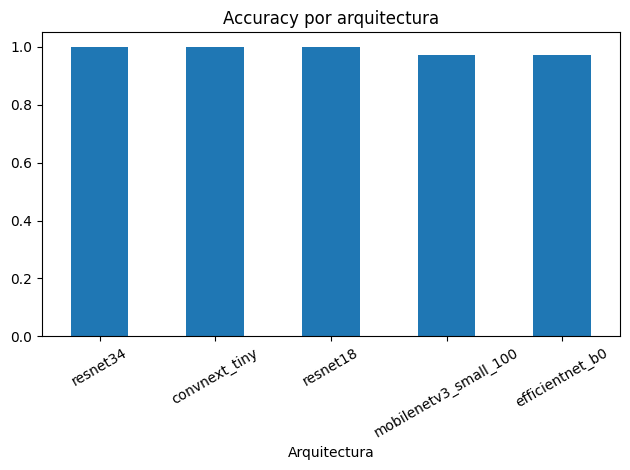

In [22]:
df.plot.bar(x='Arquitectura', y='Accuracy', legend=False)
plt.title('Accuracy por arquitectura')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

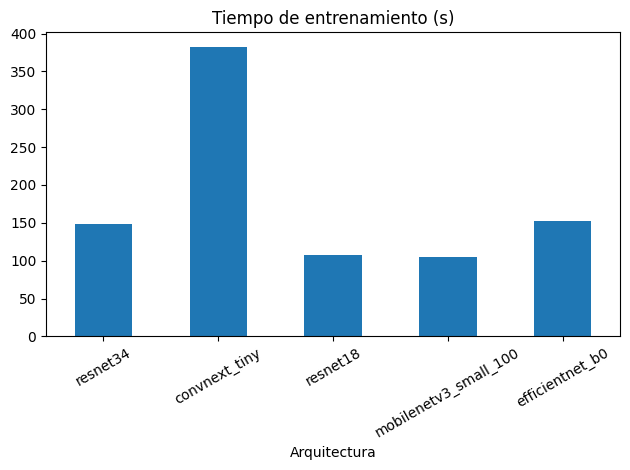

In [23]:
df.plot.bar(x='Arquitectura', y='Tiempo (s)', legend=False)
plt.title('Tiempo de entrenamiento (s)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Mostramos las matrices de los modelos que no tienen accuracy perfecta.

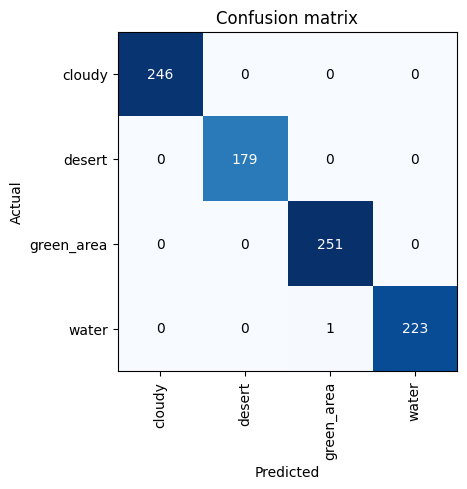

In [28]:
interp = ClassificationInterpretation.from_learner(learn_res18)
interp.plot_confusion_matrix()
plt.show()

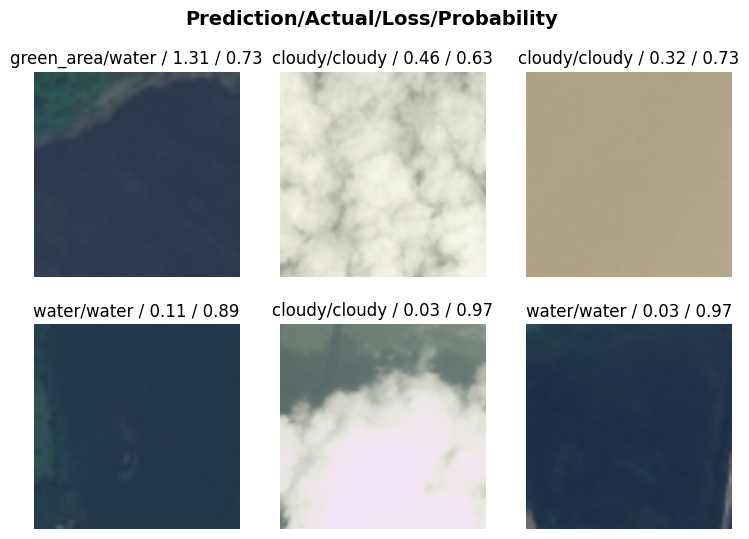

In [29]:
interp.plot_top_losses(6, nrows=2)
plt.show()

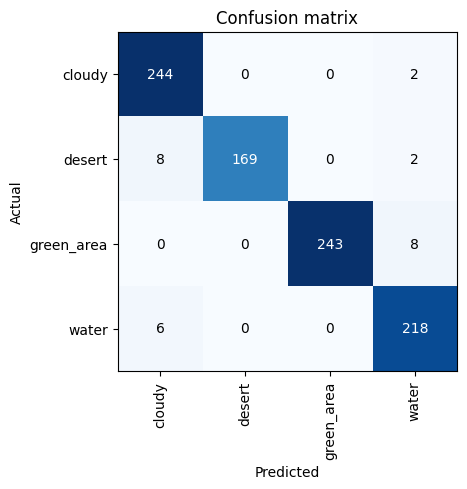

In [30]:
interp = ClassificationInterpretation.from_learner(learn_eff)
interp.plot_confusion_matrix()
plt.show()

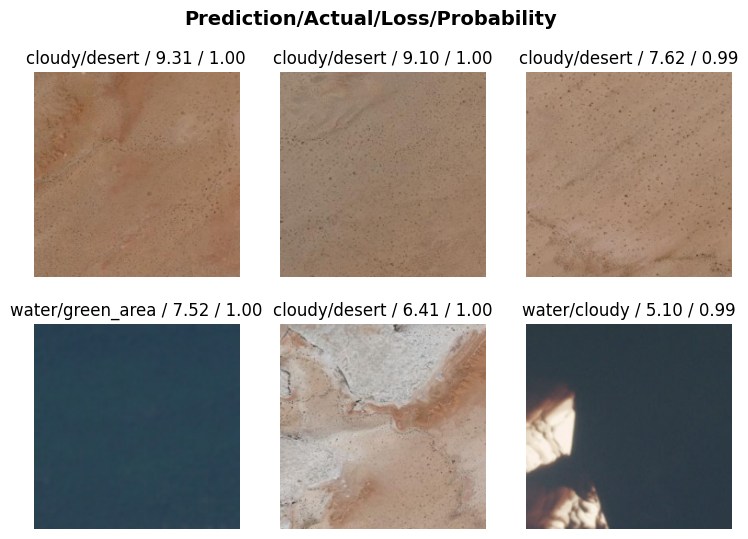

In [31]:
interp.plot_top_losses(6, nrows=2)
plt.show()

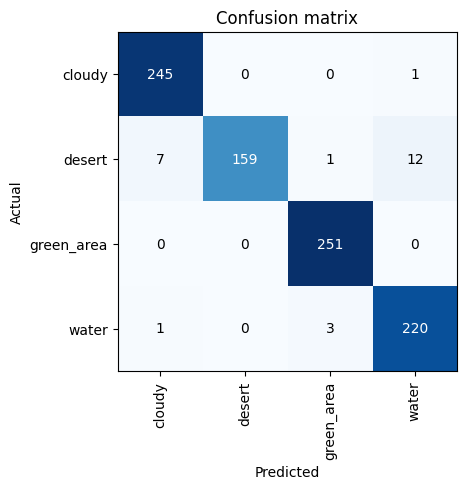

In [26]:
interp = ClassificationInterpretation.from_learner(learn_mob)
interp.plot_confusion_matrix()
plt.show()

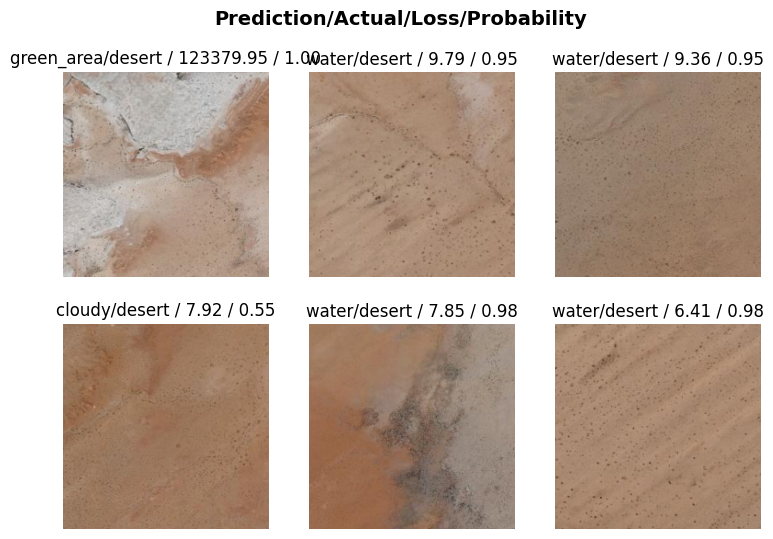

In [27]:
interp.plot_top_losses(6, nrows=2)
plt.show()

## 5. Análisis de resultados

Dos arquitecturas alcanzan accuracy perfecto que son resnet34 y convnext_tiny.
El criterio para desempatarlos es el tiempo de entrenamiento. Por un lado el tiempo de resnet34 es de 148s frente a los 382s de convnext_tiny, siendo más rápida con 10 millones menos de parámetros.

Ahjora una analisis mas profundo de las matrices de confusion de loas arquitecturas que no tubieron un accuracy perfecto.

* ResNet18: La matriz de confusión muestra un modelo casi perfecto. Vemos solo 1 imagen de water clasificada como green_area.

* EfficientNet-B0: Mayor número de errores que ResNet18 a pesar de tener accuracy similar.El patrón más claro es la confusión desert -cloudy (8 imágenes) y green_area-water (8 imágenes).

* MobileNetV3 Small: Es la arquitectura con más errores de las tres. La clase desert es la más afectadacon 7 clasificadas como cloudy y 12 como water. El top losses muestrauna pérdida extrema de 123379 en una imagen de green_area clasificada como desert, lo que junto a la val_loss de 137 indica inestabilidad numérica grave, probablemente por incompatibilidad entre el head de fastai y esta arquitectura tan ligera.

En conclusion para este dataset, resnet34 es la mejor opción considerando
accuracy, tiempo y estabilidad y que la familia ResNet es la más adecuada para el dataset satelital.